In [25]:
#Colab setup
from google.colab import drive
drive.mount('/content/drive')
import os
os.makedirs('/content/drive/MyDrive/project4', exist_ok=True)
os.chdir('/content/drive/MyDrive/project4')

import torch
print("GPU available:", torch.cuda.is_available())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU available: True


### 1. Part 1: Data Preparation and Preprocessing

In [27]:
import re
import nltk
import pandas as pd
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from sklearn.model_selection import train_test_split

# Download necessary NLTK data
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
STOP_WORDS = set(stopwords.words('english'))

df = pd.read_csv('Hotel_Reviews.csv')
pos = df['Positive_Review'].str.strip()
neg = df['Negative_Review'].str.strip()
reviews = pd.concat([pos[pos != 'No Positive'], neg[neg != 'No Negative']])
print(f"{len(reviews):,} reviews, {reviews.str.len().sum()/1e6:.1f} MB of text")

#preprocess
def preprocess(text, remove_stopwords=False):
    text = text.lower()
    text = re.sub(r'[^a-z0-9\s]', ' ', text)
    tokens = word_tokenize(text)
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]
    return ' '.join(tokens)

# Clean data
cleaned_data = [preprocess(r) for r in reviews]

# Split data into training and validation sets
train_data, val_data = train_test_split(cleaned_data, test_size=0.1, random_state=42)

# Save training and validation data
with open('train_data.txt', 'w', encoding='utf-8') as file:
    file.write('\n'.join(train_data))
with open('val_data.txt', 'w', encoding='utf-8') as file:
    file.write('\n'.join(val_data))

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


867,640 reviews, 94.0 MB of text


In [9]:
from torch.utils.data import Dataset

class TextDataset(Dataset):
    def __init__(self, tokenizer, file_path, block_size=128, max_lines=None):
        with open(file_path, 'r', encoding='utf-8') as f:
            lines = [l.strip() for l in f if l.strip()]
        # optional subset to keep a run short
        if max_lines:
            lines = lines[:max_lines]
        ids = []
        # tokenize in batches for speed
        for i in range(0, len(lines), 10_000):
            batch = tokenizer(lines[i:i+10_000])["input_ids"]
            for seq in batch:
                ids.extend(seq + [tokenizer.eos_token_id])
        self.examples = [torch.tensor(ids[i:i+block_size])
                         for i in range(0, len(ids) - block_size + 1, block_size)]
        print(f"{file_path}: {len(lines):,} lines -> {len(ids):,} tokens -> {len(self.examples):,} blocks")

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, i):
        return {"input_ids": self.examples[i], "labels": self.examples[i]}

### Part 2: Model Building and Training

In [12]:
from transformers import GPT2LMHeadModel, GPT2Tokenizer, Trainer, TrainingArguments, DataCollatorForLanguageModeling

# Load pre-trained model and tokenizer
model_name = "gpt2"
model = GPT2LMHeadModel.from_pretrained(model_name)
tokenizer = GPT2Tokenizer.from_pretrained(model_name)
tokenizer.pad_token = tokenizer.eos_token     # GPT-2 has no pad token; the collator requires one
print(model.config)

# Prepare datasets
train_dataset = TextDataset(tokenizer, "train_data.txt", block_size=128, max_lines=100_000)
val_dataset   = TextDataset(tokenizer, "val_data.txt",   block_size=128, max_lines=10_000)
data_collator = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm=False)

# Training arguments
training_args = TrainingArguments(
    output_dir="./results",
    num_train_epochs=1,
    per_device_train_batch_size=8,
    logging_steps=100,
    eval_strategy="steps",
    eval_steps=500,
    save_strategy="no",
)

# Initialize Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    data_collator=data_collator,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
)

# Train model
trainer.train()

# Save model
trainer.save_model("./trained_model")
tokenizer.save_pretrained("./trained_model")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2Config {
  "activation_function": "gelu_new",
  "add_cross_attention": false,
  "architectures": [
    "GPT2LMHeadModel"
  ],
  "attn_pdrop": 0.1,
  "bos_token_id": 50256,
  "dtype": "float32",
  "embd_pdrop": 0.1,
  "eos_token_id": 50256,
  "initializer_range": 0.02,
  "layer_norm_epsilon": 1e-05,
  "model_type": "gpt2",
  "n_ctx": 1024,
  "n_embd": 768,
  "n_head": 12,
  "n_inner": null,
  "n_layer": 12,
  "n_positions": 1024,
  "pad_token_id": null,
  "reorder_and_upcast_attn": false,
  "resid_pdrop": 0.1,
  "scale_attn_by_inverse_layer_idx": false,
  "scale_attn_weights": true,
  "summary_activation": null,
  "summary_first_dropout": 0.1,
  "summary_proj_to_labels": true,
  "summary_type": "cls_index",
  "summary_use_proj": true,
  "task_specific_params": {
    "text-generation": {
      "do_sample": true,
      "max_length": 50
    }
  },
  "tie_word_embeddings": true,
  "transformers_version": "5.18.0",
  "use_cache": true,
  "vocab_size": 50257
}

train_data.txt: 100,000 lin

Step,Training Loss,Validation Loss
500,3.944203,3.822229
1000,3.839370,3.735843
1500,3.767580,3.696034
2000,3.724272,3.675550
2167,3.736800,3.673610


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('./trained_model/tokenizer_config.json', './trained_model/tokenizer.json')

GPT-2 is chosen because GPT-2 is trained to predict the next word and can be measured with perplexity and used to generate text. Fine tuning a pretrained GPT-2 is more effective than training from scratch since 94 mb of text is small compared to the amount the GPT-2 was originally trained on.

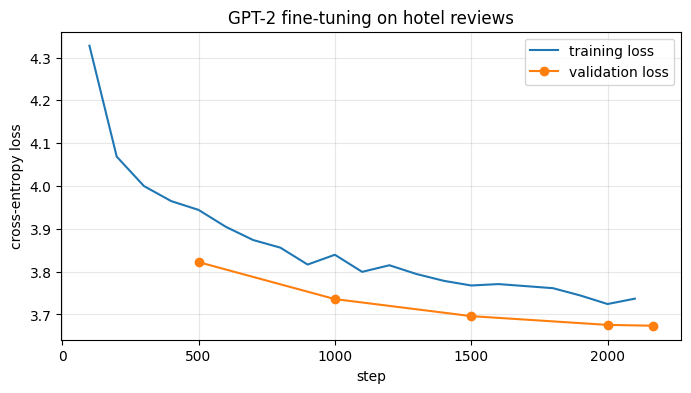

Training Loss,Validation Loss,Step
3.736800,3.673610,2167


final training loss: 3.74
final validation loss: 3.67
perplexity: 39.39


In [13]:
import math
import matplotlib.pyplot as plt

logs = trainer.state.log_history

train_pts = []
for l in logs:
    if "loss" in l:
        train_pts.append((l["step"], l["loss"]))
eval_pts = []
for l in logs:
    if "eval_loss" in l:
        eval_pts.append((l["step"], l["eval_loss"]))

#plot training vs validation loss
plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_pts), label="training loss")
plt.plot(*zip(*eval_pts), marker="o", label="validation loss")
plt.xlabel("step"); plt.ylabel("cross-entropy loss")
plt.title("GPT-2 fine-tuning on hotel reviews")
plt.legend(); plt.grid(alpha=0.3)
#plt.savefig("loss_curve.png", dpi=150, bbox_inches="tight")
plt.show()

final_eval = trainer.evaluate()
print(f"final training loss: {train_pts[-1][1]:.2f}")
print(f"final validation loss: {final_eval['eval_loss']:.2f}")
print(f"perplexity: {math.exp(final_eval['eval_loss']):.2f}")

In [14]:
#experimentation
def run_experiment(name, max_lines=50_000, learning_rate=5e-5, block_size=128, model_name="gpt2"):
    """Train one configuration on a 50k-review subset and return its validation loss / perplexity."""
    exp_model = GPT2LMHeadModel.from_pretrained(model_name)
    tr = TextDataset(tokenizer, "train_data.txt", block_size=block_size, max_lines=max_lines)
    va = TextDataset(tokenizer, "val_data.txt",   block_size=block_size, max_lines=5_000)
    args = TrainingArguments(
        output_dir=f"./results_{name}",
        num_train_epochs=1,
        per_device_train_batch_size=8,
        learning_rate=learning_rate,
        eval_strategy="no",
        save_strategy="no",
        fp16=True,
        report_to="none",
    )
    t = Trainer(model=exp_model, args=args, data_collator=data_collator, train_dataset=tr, eval_dataset=va)
    t.train()
    loss = t.evaluate()["eval_loss"]
    return {"experiment": name, "model": model_name, "train_lines": max_lines,
            "learning_rate": learning_rate, "block_size": block_size,
            "eval_loss": round(loss, 3), "perplexity": round(math.exp(loss), 2)}

results = [
    run_experiment("baseline"),                                   # 50k lines, lr 5e-5, block 128
    run_experiment("higher_lr",     learning_rate=1e-4),          # 2x learning rate
    run_experiment("short_context", block_size=64),               # half the context window
    run_experiment("distilgpt2",    model_name="distilgpt2"),     # 6 layers instead of 12
]
pd.DataFrame(results)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

train_data.txt: 50,000 lines -> 1,112,041 tokens -> 8,687 blocks
val_data.txt: 5,000 lines -> 110,880 tokens -> 866 blocks


Step,Training Loss
500,4.083210
1000,3.877974


Training Loss,Validation Loss,Step
3.877974,3.775028,1086


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

...

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

train_data.txt: 50,000 lines -> 1,112,041 tokens -> 8,687 blocks
val_data.txt: 5,000 lines -> 110,880 tokens -> 866 blocks


Step,Training Loss
500,4.313493
1000,4.081819


Training Loss,Validation Loss,Step
4.081819,3.972741,1086


,experiment,model,train_lines,learning_rate,block_size,eval_loss,perplexity
0,baseline,gpt2,50000,0.00005,128,3.775,43.60
1,higher_lr,gpt2,50000,0.00010,128,3.697,40.34
2,short_context,gpt2,50000,0.00005,64,3.742,42.18
3,distilgpt2,distilgpt2,50000,0.00005,128,3.973,53.13


### Experimentation discussion

I trained 4 versions of the model on the same 50k reviews, changing one setting each time and comparing their perplexity.

Learning rate controls how big of a step the model takes each time it updates. Learning rate had the biggest improvement, doubling it from 0.00005 to 0.00010 lowered perplexity from 43.6 to 40.34.

Changing context length by cutting block size from 128 to 64 changed perplexity from 43.6 to 42.18. This may be due to hotel reviews being shorter so the model doesn't need a long context window and smaller blocks mean more training steps from the same data.

For model size we used DistilGPT-2 which has half the layers of of GPT-2. DistilGPT-2 trained twice as fast but it has less capacity to learn the vocab and patterns of reviews. DistilGPT-2 score 53.1 which is around 22% worse.

Lastly for amount of data we trained on 100k reviews instead of 50k reviews. This gave a perplexity score of 39.39, which is better than any of the single setting changes.

### Part 3: Model Evaluation


In [17]:

# Evaluate model using perplexity
import math
from transformers import pipeline

# Load trained model and tokenizer
model = GPT2LMHeadModel.from_pretrained("./trained_model")
tokenizer = GPT2Tokenizer.from_pretrained("./trained_model")

# Text generation
text_generator = pipeline("text-generation", model=model, tokenizer=tokenizer, device=0)
prompt = "the room was"
generated_text = text_generator(prompt, max_new_tokens=40, pad_token_id=tokenizer.eos_token_id)
print(generated_text)

# Perplexity calculation: fine-tuned model
trainer.model = model
eval_results = trainer.evaluate()
perplexity = math.exp(eval_results['eval_loss'])
print(f"Fine-tuned GPT-2 perplexity: {perplexity:.2f}")

#original GPT-2 perplexity calculation as a baseline
base_model = GPT2LMHeadModel.from_pretrained("gpt2")
base_args = TrainingArguments(output_dir="./results_base", fp16=True, report_to="none")
base_trainer = Trainer(model=base_model, args=training_args, data_collator=data_collator, eval_dataset=val_dataset)
base_perplexity = math.exp(base_trainer.evaluate()['eval_loss'])
print(f"Original GPT-2 perplexity:   {base_perplexity:.2f}")
print(f"Fine-tuning reduced perplexity by {100*(1 - perplexity/base_perplexity):.0f}%")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=40) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[{'generated_text': 'the room was too small no space to put the blankets and had to close the door to reach the window at night although the bed was soft there was a gap in the shower which made it difficult to shower again it'}]


Training Loss,Validation Loss,Step
3.736800,3.673610,2167


Fine-tuned GPT-2 perplexity: 39.39


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Training Loss,Validation Loss,Step
No log,5.213210,0


Original GPT-2 perplexity:   183.68
Fine-tuning reduced perplexity by 79%


In [19]:
#Other relevant metrics
#Next word prediction accuracy
import torch

def next_token_accuracy(model, dataset, n_blocks=500):
    model.eval()
    device = next(model.parameters()).device
    correct = total = 0
    with torch.no_grad():
        for i in range(min(n_blocks, len(dataset))):
            ids = dataset[i]["input_ids"].unsqueeze(0).to(device)
            preds = model(ids).logits[0, :-1].argmax(-1)
            correct += (preds == ids[0, 1:]).sum().item()
            total += preds.numel()
    return correct / total

acc_ft   = next_token_accuracy(model, val_dataset)
acc_base = next_token_accuracy(base_model, val_dataset)
print(f"Next-word accuracy  fine-tuned: {acc_ft:.1%}   original GPT-2: {acc_base:.1%}")

Next-word accuracy  fine-tuned: 29.2%   original GPT-2: 18.0%


### Performance Analysis
| Metric | Original GPT-2 | Fine-tuned GPT-2 |
|---|---|---|
| Validation loss | 5.213 | 3.674 |
| Perplexity | 183.68 | 39.39 |
| Next-word accuracy | 18.0% | 29.2% |

Fine tuning cut perplexity from 183.68 to 39.39 which is a 79% reduction. The original GPT-2 was trained on normal web text so lowercase, punctuation free reviews are unfamiliar to it. With one epoch on 100k reviews taught the model on format and vocab for the dataset.

Next word accuracy rose from 18% to 29.2%.

From both metrics, the fine tune model performed better at predicting the hotel review text than the original.

### Part 4: Application

In [20]:
from transformers import GPT2LMHeadModel, GPT2Tokenizer, pipeline

# Load the trained model and tokenizer
model_path = "./trained_model"
model = GPT2LMHeadModel.from_pretrained(model_path)
tokenizer = GPT2Tokenizer.from_pretrained("gpt2")

# Create a text generation pipeline
text_generator = pipeline("text-generation", model=model, tokenizer=tokenizer, device=0)

# Define prompts (lowercase, like the training data)
prompt = [
    "the room was",
    "the staff were",
    "breakfast was",
    "the location of the hotel",
    "would not recommend because",
]

# Generate text
for p in prompt:
    generated_text = text_generator(p, max_length=100, num_return_sequences=1)

    # Display the generated text
    print(f"PROMPT: {p}")
    for i, text in enumerate(generated_text):
        print(f"  Generated Text {i + 1}: {text['generated_text']}")
    print()

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'num_return_sequences', 'max_length'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=256) and `max_length`(=100) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=100) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


PROMPT: the room was
  Generated Text 1: the room was too small no space to put the blankets and had to close the door to reach the window at night although the bed was soft there was a gap in the shower which made it difficult to shower again it was also very uncomfortable for us to have a bath on and we had to sleep on the floor opposite of the bed in other rooms we had to climb up and down to the opposite side of the bed to get out of it and the floor had no air conditioning we had to climb up and down again to get out of it to get a good night sleep we didn t like the fact that the lift outside the door was only accessible by staff who were very rude and very rude we never got a refund for the room we stayed in for the rest of our stay and were forced to pay to get a refund on the first room we stayed in i understand this is not the fault of the hotel but it was the fault of the staff who were really rude and very rude the room was very small and had no view to the street we were t

[transformers] Both `max_new_tokens` (=256) and `max_length`(=100) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


PROMPT: the staff were
  Generated Text 1: the staff were superb the location was excellent and the rooms were very quiet the staff were very helpful and friendly the room was very clean and the pool is very good the hotel was clean and well presented with the best views of the city we will definitely stay here again but the staff was extremely helpful and very friendly the room and bathroom were well appointed and the shower was excellent the staff were very helpful and friendly and the hotel was very clean and modern the location was convenient for the sightseeing and the city center was near the tram stop and the metro station was also within walking distance the location is very close to the shops and restaurants the breakfast was very good and the facilities were great the staff were fantastic we will definitely stay here again the room and bathroom were very good and the location is near to the subway station and a short walk to the museums and the shopping area and the staff wer

[transformers] Both `max_new_tokens` (=256) and `max_length`(=100) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


PROMPT: breakfast was
  Generated Text 1: breakfast was fantastic and the staff were very helpful and friendly the location is perfect for the airport and the tram stop is a short walk away the pool is really great and the staff were super helpful and friendly the staff were really helpful and friendly with all the questions we had the location was close to the main tube station the rooftop bar was also great and the room was very comfy and clean the room and bedroom were very clean and well appointed and the location was perfect for the trip to paris we will definitely be back again this is a very nice hotel and would definitely recommend it as we enjoyed our stay at this hotel so much the staff were very nice and helpful we will definitely be returning and will definitely stay there again in paris next time i will be back thank you again for a wonderful stay i will definitely be back to paris again and will definitely return to paris for a very special holiday for our stay the hotel 

[transformers] Both `max_new_tokens` (=256) and `max_length`(=100) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


PROMPT: the location of the hotel
  Generated Text 1: the location of the hotel in particular was amazing as was the breakfast and the service which was great the hotel was a 2 minute walk from oxford street and a good 10 minute walk to the oxford road station which was a lovely change of pace from the big city to the quiet small town of oxford street we really enjoyed our stay at this hotel and would highly recommend to others traveling to london and west end for the next three years of our lives it was a great choice of breakfast and the staff were always very helpful and always smiling the location of the hotel means it is a little close to a few attractions although the tube stops to the south west and to the far west bank i would definitely come back again when visiting london very much for the money and the location is great too if you are travelling at night the hotel is quiet and is easy to get to and you can easily walk to the airport from the hotel itself the hotel also has a

### Part 4 discussion

I gave the model 5 prompts and outputs were pretty coherent and read like real hotel reviews. Sentiments usually match the prompt for example "breakfast was" and "tje staff were" produced positive reviews why "the room was" produced a negative review. Some problems were repetition where "the staff were very helpful and friendly" show up in multiple prompts and contradiction happened such as "the bathroom was also very small and it was very big". The prompts also dont have a clear ending since the training text has no punctuation and the generated text were long leading to outputs running several reviews together instead of stopping when a review is finished.


#### Fine-tuning

In [ ]:
##### Load and Preprocess the Dataset

In [21]:
import pandas as pd
from sklearn.model_selection import train_test_split
from datasets import Dataset

# Load the dataset
data_path = "Hotel_Reviews.csv"
df = pd.read_csv(data_path)

# Preprocess the dataset: positive reviews -> label 1, negative reviews -> label 0
pos_df = pd.DataFrame({'review': df['Positive_Review'], 'label': 1})
neg_df = pd.DataFrame({'review': df['Negative_Review'], 'label': 0})
df = pd.concat([pos_df[pos_df['review'].str.strip() != 'No Positive'].sample(20_000, random_state=42), neg_df[neg_df['review'].str.strip() != 'No Negative'].sample(20_000, random_state=42)])
train_df, val_df = train_test_split(df, test_size=0.1, stratify=df['label'])

# Convert to Hugging Face Dataset format
train_dataset = Dataset.from_pandas(train_df[['review', 'label']])
val_dataset = Dataset.from_pandas(val_df[['review', 'label']])

# Tokenize the dataset
tokenizer.pad_token = tokenizer.eos_token
def tokenize_function(examples):
    return tokenizer(examples['review'], truncation=True, padding='max_length', max_length=128)

train_dataset = train_dataset.map(tokenize_function, batched=True)
val_dataset = val_dataset.map(tokenize_function, batched=True)

# Set format for PyTorch
train_dataset.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])
val_dataset.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])

Map:   0%|          | 0/36000 [00:00<?, ? examples/s]

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

#### Fine-tune the Model

In [23]:
from transformers import Trainer, TrainingArguments, GPT2ForSequenceClassification

# Load the pretrained GPT2 model for sequence classification
model = GPT2ForSequenceClassification.from_pretrained("gpt2", num_labels=2)
model.config.pad_token_id = tokenizer.pad_token_id

# Training arguments
training_args = TrainingArguments(
    output_dir="./results",
    num_train_epochs=1,
    per_device_train_batch_size=8,
    eval_strategy="epoch",
    save_steps=10_000,
    save_total_limit=2,
)

# Initialize Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
)

# Train model
trainer.train()

# Save the fine-tuned model
trainer.save_model("./fine_tuned_model")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] GPT2ForSequenceClassification LOAD REPORT from: gpt2
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss
1,0.192222,0.235617


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

#####Evaluate the Fine-tuned Model

In [24]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# Define a function to compute metrics
def compute_metrics(p):
    preds = p.predictions.argmax(-1)
    precision, recall, f1, _ = precision_recall_fscore_support(p.label_ids, preds, average='binary')
    acc = accuracy_score(p.label_ids, preds)
    return {
        'accuracy': acc,
        'precision': precision,
        'recall': recall,
        'f1': f1,
    }

# Load the fine-tuned model
model = GPT2ForSequenceClassification.from_pretrained("./fine_tuned_model")

# Initialize the Trainer for evaluation
trainer = Trainer(
    model=model,
    args=training_args,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics,
)

# Evaluate the model
eval_results = trainer.evaluate()
print(eval_results)


Loading weights:   0%|          | 0/149 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
No log,0.235617,0,0.940000,0.939560,0.940500,0.940030


{'eval_loss': 0.23561689257621765, 'eval_accuracy': 0.94, 'eval_precision': 0.9395604395604396, 'eval_recall': 0.9405, 'eval_f1': 0.9400299850074962}


### Fine-tuning discussion
GPT-2 was fined tuned on 36k reviews balanced between positive and negative and evaluated on 4k held out reviews. A 94% accuracy shows that the model has learned to tell positive from negative reviews. Precision and recall is almost idetical so it shows that the model doesnt lean toward either negative nor positive. Since the pretrained GPT-2 model already understands english it only needs to learn which words and phrases signal positive or negative. Training on more avaiable reviews would likely push accuracy to higher than 94%.